In [2]:
# Python 3.14.7
#* Imports
import numpy as np #2.5.3
import matplotlib.pyplot as plt #3.11.2
from scipy import stats #1.18.1

#* Ploting style snippet for consistency.
plt.rcParams.update({
    "font.size": 18,
    "font.family": "serif",
    "figure.autolayout": True,
    "axes.grid": False,
    # "xtick.minor.visible": True,
    # "ytick.minor.visible": True,
})



### Activity 1: Central Limit Theorem

<>:36: SyntaxWarning: "\m" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\m"? A raw string is also an option.
<>:38: SyntaxWarning: "\m" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\m"? A raw string is also an option.
<>:36: SyntaxWarning: "\m" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\m"? A raw string is also an option.
<>:38: SyntaxWarning: "\m" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\m"? A raw string is also an option.
C:\Users\bleicester\AppData\Local\Temp\ipykernel_17624\1462507062.py:36: SyntaxWarning: "\m" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\m"? A raw string is also an option.
  ax[ind].set(xlabel="$\mu$")
C:\Users\bleicester\AppData\Local\Temp\ipykernel_17624\1462507062.py:38: SyntaxWarning: "\m" is an invalid escape sequence. Such seque

array([[<Axes: ylabel='$P(\\mu)$'>, <Axes: >, <Axes: >],
       [<Axes: xlabel='$\\mu$', ylabel='$P(\\mu)$'>,
        <Axes: xlabel='$\\mu$'>, <Axes: xlabel='$\\mu$'>]], dtype=object)

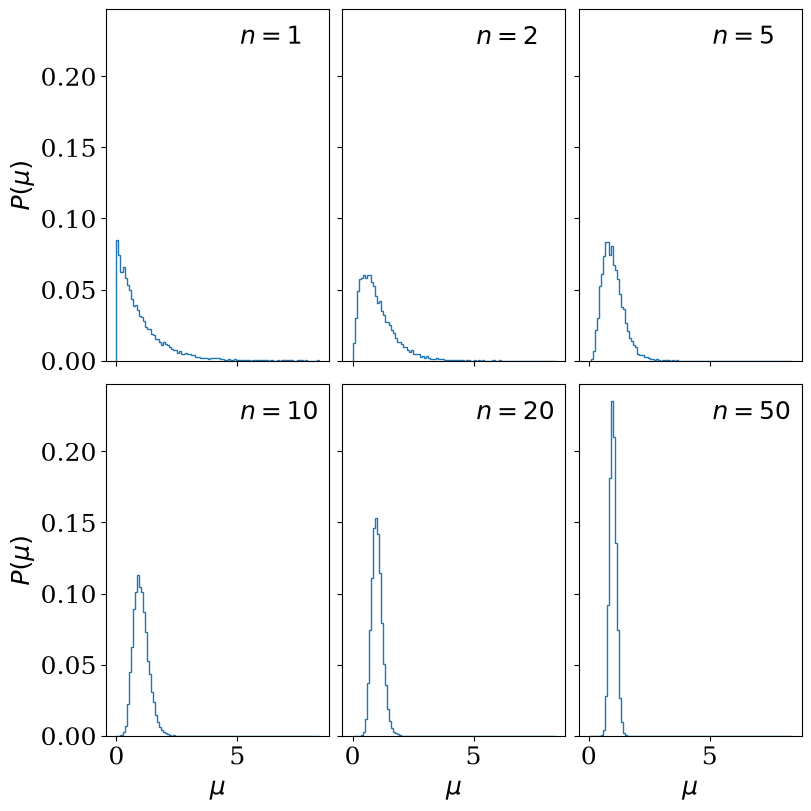

In [3]:
def s_draw():
    rng = np.random.default_rng()

    return - np.log(rng.random())

m=10000


fig,ax = plt.subplots(2,3, figsize=(8,8), layout="constrained", sharex=True, sharey=True)

ax = np.ravel(ax)

for ind, n in enumerate([1,2,5,10,20,50]):
    mus = []

    for j in range(m):
        draws = []
        for i in range(n):
            draws.append(s_draw())

        mu = np.mean(draws)
        mus.append(mu)

    if ind == 0:
        bins = np.linspace(0,np.max(mus),101) #* Same bins for each run, from largest spread of values

    hist,_ = np.histogram(mus, bins)

    hist = hist/ np.sum(hist)

    # print(np.sum(hist)) #* == 1 to float precision

    ax[ind].stairs(hist, bins)

    if ind >2:
        ax[ind].set(xlabel="$\mu$")
    if ind%3==0:
        ax[ind].set(ylabel="$P(\mu)$")
    
    ax[ind].text(0.6, 0.9, f"$n={n}$", transform=ax[ind].transAxes)


ax.reshape(2,3)

I Think fixing the $x$ and $y$ lims to be the same in each panel helps show how the distributions change with $n$ 

### Activity 2: Neutron Star Masses

For the NS datasets, the t statistic for sets sharing a mean is -3.1064, with significance 0.0028
The KS test has a statistic d=0.6150, with significance 0.000076


<>:17: SyntaxWarning: "\m" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\m"? A raw string is also an option.
<>:21: SyntaxWarning: "\o" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\o"? A raw string is also an option.
<>:17: SyntaxWarning: "\m" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\m"? A raw string is also an option.
<>:21: SyntaxWarning: "\o" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\o"? A raw string is also an option.
C:\Users\bleicester\AppData\Local\Temp\ipykernel_17624\3233034505.py:17: SyntaxWarning: "\m" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\m"? A raw string is also an option.
  ax[0].axvline(doub_ns.mean(), c="k", ls="--", label="$\mu$")
C:\Users\bleicester\AppData\Local\Temp\ipykernel_17624\3233034505.py:21: SyntaxWarning: "\o" is an in

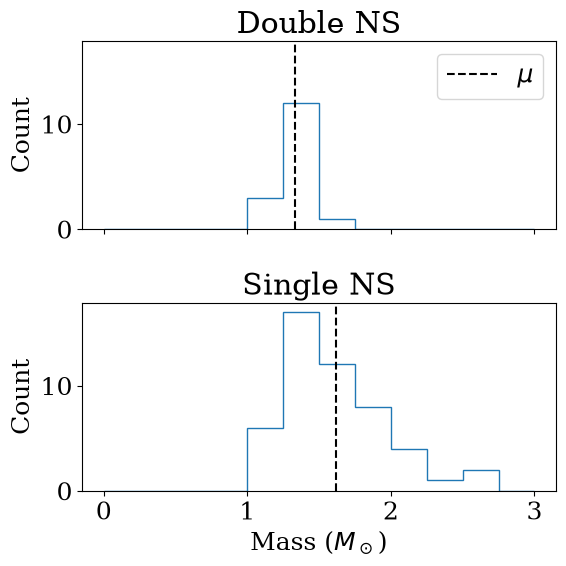

In [4]:
doub_ns = np.loadtxt("../Datasets/ns_masses1.dat")

sing_ns = np.loadtxt("../Datasets/ns_masses2.dat")

ns_means_t, ns_means_p = stats.ttest_ind(doub_ns, sing_ns)
print(f"For the NS datasets, the t statistic for sets sharing a mean is {ns_means_t:.4f}, with significance {ns_means_p:.4f}")

ns_ks_d, ns_ks_p = stats.ks_2samp(doub_ns, sing_ns)
print(f"The KS test has a statistic d={ns_ks_d:.4f}, with significance {ns_ks_p:.6f}")


fig, ax  = plt.subplots(2,figsize=(6,6), sharex=True, sharey=True)

bins = np.linspace(0,3,13)

ax[0].stairs(*np.histogram(doub_ns,bins))
ax[0].axvline(doub_ns.mean(), c="k", ls="--", label="$\mu$")
ax[0].set(title="Double NS", ylabel="Count")
ax[1].stairs(*np.histogram(sing_ns,bins))
ax[1].axvline(sing_ns.mean(), c="k", ls="--")
ax[1].set(title="Single NS", xlabel = "Mass ($M_\odot$)",ylabel="Count")

ax[0].legend()